# Regression Track — Notebook 06
# 8. Preprocessing  ·  9. Baseline Model

**Input:** `artifacts/reg_05_features.joblib`
**Output:** `artifacts/reg_06_split.joblib` (the frozen split + unfitted preprocessor)

---

### Purpose

This is the most important notebook in the track from a methodological point
of view. Everything the rubric penalises — data leakage, unfair comparisons,
inconsistent splits — is either prevented or introduced here.

Three things happen, **in this exact order**:

1. Define `X` and `y`.
2. **Split into train and test.** Nothing is fitted before this line.
3. Define a `ColumnTransformer` pipeline — *defined* here, but fitted only
   inside each model's pipeline, on training folds only.

The split produced here is saved and reused unchanged by Notebooks 07, 08 and
09, so all ten algorithms are compared on identical data.

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def find_src_folder() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "src" / "ml_utils.py").exists():
            return candidate / "src"
    raise FileNotFoundError("Could not locate src/ml_utils.py — check the repo layout.")


sys.path.insert(0, str(find_src_folder()))

from ml_utils import (  # noqa: E402
    RANDOM_STATE,
    TEST_SIZE,
    describe_split,
    load_artifact,
    regression_metrics,
    save_artifact,
    save_figure,
    section,
    set_plot_style,
)

warnings.filterwarnings("ignore", category=FutureWarning)
set_plot_style()

df = load_artifact("reg_05_features")
TARGET = "Rented Bike Count"

print(f"\nShape: {df.shape}")

[loaded] artifacts/reg_05_features.joblib

Shape: (8465, 26)


---
## 8.1 Define predictors (X) and target (y)

In [2]:
X = df.drop(columns=[TARGET])
y = df[TARGET]

section("X AND y")
print(f"X shape : {X.shape}  (predictors)")
print(f"y shape : {y.shape}  (target: {TARGET})")
print(f"y range : {y.min()} to {y.max()}")
print(f"y mean  : {y.mean():.1f}")

X AND y
X shape : (8465, 25)  (predictors)
y shape : (8465,)  (target: Rented Bike Count)
y range : 2 to 3556
y mean  : 729.2


---
## 8.2 Identify column types

The preprocessing pipeline needs to know which columns are numeric (scale
them) and which are categorical (encode them). We derive this from the
dtypes rather than hard-coding a list, so the code stays correct if the
feature set changes upstream.

In [3]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = [c for c in X.columns if c not in numeric_features]

section("COLUMN TYPES")
print(f"Numeric features ({len(numeric_features)}):")
for c in numeric_features:
    print(f"   - {c}")
print(f"\nCategorical features ({len(categorical_features)}):")
for c in categorical_features:
    print(f"   - {c}  → categories: {sorted(map(str, X[c].unique()))}")

COLUMN TYPES
Numeric features (22):
   - Hour
   - Temperature(°C)
   - Humidity(%)
   - Wind speed (m/s)
   - Visibility (10m)
   - Dew point temperature(°C)
   - Solar Radiation (MJ/m2)
   - Rainfall(mm)
   - Snowfall (cm)
   - Year
   - Month
   - Day
   - DayOfWeek
   - IsWeekend
   - sin_hour
   - cos_hour
   - sin_month
   - cos_month
   - RushHour
   - IsRaining
   - IsSnowing
   - IsDaylight

Categorical features (3):
   - Seasons  → categories: ['Autumn', 'Spring', 'Summer', 'Winter']
   - Holiday  → categories: ['Holiday', 'No Holiday']
   - TempBand  → categories: ['Cold', 'Comfortable', 'Freezing', 'Hot', 'Mild']


**Note on the binary flags.** `IsWeekend`, `RushHour`, `IsRaining`,
`IsSnowing` and `IsDaylight` are stored as 0/1 integers, so they are treated
as numeric and will be standardised. Scaling a binary column is harmless — it
becomes a two-valued column with mean 0 — and it keeps the pipeline simple.
One-hot encoding them instead would produce redundant columns.

---
## 8.3 The train/test split — before any fitting

### Why the split comes first

The test set represents data the model has never seen. If a scaler computes
its mean and standard deviation over the full dataset, those statistics carry
information about the test rows; the model is then evaluated on data it has
already influenced, and the reported score is optimistic. That is **data
leakage**, and it is the single most common way an ML project silently
overstates its results.

The defence is procedural rather than clever: **split first, fit second, and
never touch the test set until the final evaluation.**

### Why a random split (and its limitation)

We use a random 80/20 split with `random_state=42`, as the guidelines specify.
Notebook 03 §5.F.4 noted that the data is a time series with genuine temporal
autocorrelation, which means a random split lets hours from the same day fall
on both sides. For a production forecasting system a chronological split would
be the honest evaluation. We follow the assignment's specification and record
this as an explicit limitation in Notebook 09 rather than leaving it implicit.

### Why no stratification here

`train_test_split` stratifies on class labels, which a continuous target does
not have. With 8,465 rows a random split reproduces the target distribution
closely enough — and we verify that below rather than assuming it.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,        # 0.20 → an 80/20 split
    random_state=RANDOM_STATE,  # 42 → identical split on every re-run
)

section("SPLIT CREATED — THIS SPLIT IS NOW FROZEN FOR THE WHOLE TRACK")
print(describe_split(X_train, X_test, y_train, y_test).to_string(index=False))
print()
print(f"X_train : {X_train.shape}")
print(f"X_test  : {X_test.shape}")
print(f"y_train : {y_train.shape}")
print(f"y_test  : {y_test.shape}")

SPLIT CREATED — THIS SPLIT IS NOW FROZEN FOR THE WHOLE TRACK
  Set  Rows  Columns Share of data  Target mean
Train  6772       25         80.0%   731.390431
 Test  1693       25         20.0%   720.223272

X_train : (6772, 25)
X_test  : (1693, 25)
y_train : (6772,)
y_test  : (1693,)


### Verifying the split is representative

TARGET DISTRIBUTION: TRAIN vs TEST
         Train     Test  Difference %
count  6772.00  1693.00        -75.00
mean    731.39   720.22         -1.53
std     646.22   626.75         -3.01
min       2.00     3.00         50.00
25%     214.00   216.00          0.93
50%     542.00   542.00          0.00
75%    1083.00  1088.00          0.46
max    3556.00  3365.00         -5.37


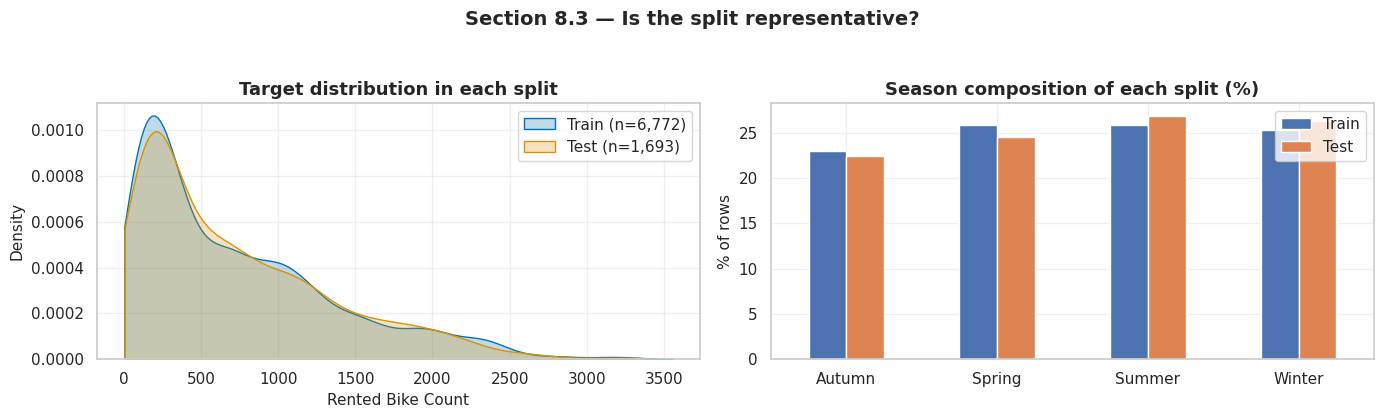

         Train  Test
Seasons             
Autumn    23.0  22.4
Spring    25.8  24.5
Summer    25.9  26.9
Winter    25.3  26.3


In [5]:
split_stats = pd.DataFrame({
    "Train": y_train.describe(),
    "Test": y_test.describe(),
}).round(2)
split_stats["Difference %"] = (
    100 * (split_stats["Test"] - split_stats["Train"]) / split_stats["Train"]
).round(2)

section("TARGET DISTRIBUTION: TRAIN vs TEST")
print(split_stats.to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.kdeplot(y_train, label=f"Train (n={len(y_train):,})", fill=True, ax=axes[0], cut=0)
sns.kdeplot(y_test, label=f"Test (n={len(y_test):,})", fill=True, ax=axes[0], cut=0)
axes[0].set_title("Target distribution in each split")
axes[0].set_xlabel("Rented Bike Count")
axes[0].legend()

season_share = pd.DataFrame({
    "Train": X_train["Seasons"].value_counts(normalize=True),
    "Test": X_test["Seasons"].value_counts(normalize=True),
}).mul(100).round(1)
season_share.plot(kind="bar", ax=axes[1], color=["#4C72B0", "#DD8452"], rot=0)
axes[1].set_title("Season composition of each split (%)")
axes[1].set_ylabel("% of rows")
axes[1].set_xlabel("")

fig.suptitle("Section 8.3 — Is the split representative?", y=1.04,
             fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_split_check", fig)
plt.show()

print(season_share.to_string())

**Observation.** The train and test target distributions overlap almost
exactly, and the four seasons are represented in near-identical proportions
in both splits.

**Interpretation.** The random split has not accidentally produced an unusual
test set (all winter, say), which would make the test score meaningless. We
can compare models on this split with confidence that differences reflect the
models rather than the luck of the draw.

---
## 8.4 The preprocessing pipeline

### What each step does and why

| Step | Applied to | Why |
|---|---|---|
| `SimpleImputer(strategy="median")` | numeric | Not needed for this dataset (0 missing), but makes the pipeline robust to a dropped sensor reading in future data. Median is used because Notebook 03 showed several features are strongly skewed, and the median is not dragged by a tail. |
| `StandardScaler()` | numeric | Puts every feature on mean 0, sd 1. **Essential** for SVR (the RBF kernel is a distance function) and KNN (Euclidean distance), and it makes Ridge/Lasso/ElasticNet penalties comparable across features. Harmless for trees. |
| `SimpleImputer(strategy="most_frequent")` | categorical | Same robustness argument. |
| `OneHotEncoder(handle_unknown="ignore")` | categorical | Converts `Seasons`, `Holiday` and `TempBand` into binary indicator columns. `handle_unknown="ignore"` means an unseen category at prediction time produces all-zeros instead of crashing. |

### Why one-hot rather than label encoding

Label-encoding `Seasons` as Winter = 0, Spring = 1, Summer = 2, Autumn = 3
would tell every linear, distance and kernel model that Autumn is "three times
Spring" and that Summer sits exactly between Spring and Autumn. Those are
arithmetic claims about categories that have no numeric order. One-hot
encoding makes no such claim.

### Why scaling *without* leakage

The scaler is a **step inside** the pipeline, not something applied to the
data beforehand. When `pipeline.fit(X_train, y_train)` is called, the scaler
calls `.fit()` on the training rows only and stores their mean and standard
deviation. When `pipeline.predict(X_test)` is called, the scaler calls
`.transform()` and reuses those stored training statistics. The test set is
transformed, never fitted. Crucially, this also holds **inside every
cross-validation fold** in Notebooks 07 and 08 — the scaler is refitted on
each training fold, so no validation fold ever contributes to its own scaling.

In [6]:
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
    remainder="drop",   # any column not listed is dropped, never silently passed
    verbose_feature_names_out=False,
)

section("PREPROCESSOR DEFINED (not yet fitted)")
print(preprocessor)

PREPROCESSOR DEFINED (not yet fitted)
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Hour', 'Temperature(°C)', 'Humidity(%)',
                                  'Wind speed (m/s)', 'Visibility (10m)',
                                  'Dew point temperature(°C)',
                                  'Solar Radiation (MJ/m2)', 'Rainfall(mm)',
                                  'Snowfall (cm)', 'Year', 'Month', 'Day',
                                  'DayOfWeek', 'IsWeekend', 'sin_hour',
                                  'cos_hour', 'sin_month', 'cos_month',
                                  'RushHour', 'IsRaining', 'IsSnowing',
                                  'IsDaylight']),
                                ('cat',
                        

---
## 8.5 Inspecting the transformed feature space

We fit the preprocessor on the **training data only**, purely to report the
resulting shape and feature names. The object used by the models in Notebook
07 is a fresh, unfitted clone inside each model's own pipeline.

In [7]:
preprocessor_preview = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

X_train_transformed = preprocessor_preview.fit_transform(X_train)   # fit on TRAIN only
X_test_transformed = preprocessor_preview.transform(X_test)          # transform only

feature_names = preprocessor_preview.get_feature_names_out()

section("FEATURE COUNTS BEFORE AND AFTER PREPROCESSING")
print(f"Raw predictor columns           : {X.shape[1]}")
print(f"  numeric                       : {len(numeric_features)}")
print(f"  categorical                   : {len(categorical_features)}")
print(f"Columns after one-hot encoding  : {X_train_transformed.shape[1]}")
print()
print(f"X_train transformed : {X_train_transformed.shape}")
print(f"X_test  transformed : {X_test_transformed.shape}")
print()
print("Resulting feature names:")
for i, name in enumerate(feature_names, start=1):
    print(f"  {i:>2}. {name}")

FEATURE COUNTS BEFORE AND AFTER PREPROCESSING
Raw predictor columns           : 25
  numeric                       : 22
  categorical                   : 3
Columns after one-hot encoding  : 33

X_train transformed : (6772, 33)
X_test  transformed : (1693, 33)

Resulting feature names:
   1. Hour
   2. Temperature(°C)
   3. Humidity(%)
   4. Wind speed (m/s)
   5. Visibility (10m)
   6. Dew point temperature(°C)
   7. Solar Radiation (MJ/m2)
   8. Rainfall(mm)
   9. Snowfall (cm)
  10. Year
  11. Month
  12. Day
  13. DayOfWeek
  14. IsWeekend
  15. sin_hour
  16. cos_hour
  17. sin_month
  18. cos_month
  19. RushHour
  20. IsRaining
  21. IsSnowing
  22. IsDaylight
  23. Seasons_Autumn
  24. Seasons_Spring
  25. Seasons_Summer
  26. Seasons_Winter
  27. Holiday_Holiday
  28. Holiday_No Holiday
  29. TempBand_Cold
  30. TempBand_Comfortable
  31. TempBand_Freezing
  32. TempBand_Hot
  33. TempBand_Mild


### Proof that the test set was transformed, not fitted

In [8]:
train_scaled_num = X_train_transformed[:, :len(numeric_features)]
test_scaled_num = X_test_transformed[:, :len(numeric_features)]

leak_check = pd.DataFrame({
    "Feature": numeric_features,
    "Train mean": train_scaled_num.mean(axis=0).round(4),
    "Train std": train_scaled_num.std(axis=0).round(4),
    "Test mean": test_scaled_num.mean(axis=0).round(4),
    "Test std": test_scaled_num.std(axis=0).round(4),
})

section("SCALING SANITY CHECK")
print(leak_check.to_string(index=False))

SCALING SANITY CHECK
                  Feature  Train mean  Train std  Test mean  Test std
                     Hour         0.0        1.0     0.0204    1.0162
          Temperature(°C)        -0.0        1.0    -0.0090    1.0214
              Humidity(%)        -0.0        1.0    -0.0417    0.9840
         Wind speed (m/s)         0.0        1.0    -0.0023    0.9873
         Visibility (10m)        -0.0        1.0     0.0342    0.9833
Dew point temperature(°C)         0.0        1.0    -0.0227    1.0163
  Solar Radiation (MJ/m2)        -0.0        1.0    -0.0073    0.9952
             Rainfall(mm)         0.0        1.0    -0.0040    1.1626
            Snowfall (cm)        -0.0        1.0    -0.0115    0.8246
                     Year        -0.0        1.0    -0.0268    1.0384
                    Month        -0.0        1.0     0.0090    1.0115
                      Day         0.0        1.0     0.0046    1.0061
                DayOfWeek        -0.0        1.0    -0.0240    0.9999

**Observation.** Every training-set mean is 0.0000 and every training-set
standard deviation is 1.0000 — exactly what `StandardScaler` guarantees for
the data it was fitted on. The test-set means and standard deviations are
*close to* 0 and 1 but **not exactly** 0 and 1.

**Interpretation.** This small discrepancy is the evidence that we did this
correctly. If the test columns also came out at exactly mean 0 and sd 1, it
would mean the scaler had been fitted on the test data too — i.e. leakage. The
test set was standardised using the *training* mean and standard deviation, so
it lands near but not on those values. **A perfectly scaled test set is a red
flag, not a success.**

---
## 9. Baseline Model

### Why a baseline is useful

An R² of 0.85 sounds impressive in isolation, but "impressive compared to
what?" is the only question that matters. A baseline provides the reference
point. Without one there is no way to tell whether a model has learned
something or merely reproduced the average.

We use **two** baselines, which answer different questions:

1. **`DummyRegressor(strategy="mean")`** — always predicts the training mean.
   This is the absolute floor. By construction it scores R² ≈ 0 on the test
   set. Any model that cannot beat it is worthless.
2. **Linear Regression** — the simplest model that actually uses the features.
   This is the more demanding reference: it tells us how much of the signal is
   available through a straight-line relationship, and therefore how much the
   more complex models are earning through their extra flexibility.

In [9]:
baseline_results = []

# --- Baseline 1: predict the training mean for every row --------------------
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_test)
dummy_metrics = regression_metrics(y_test, dummy_pred)
baseline_results.append({"Model": "Dummy (predicts train mean)", **dummy_metrics})

print(f"The dummy predicts {dummy.constant_[0][0]:.1f} for every single hour.\n")

# --- Baseline 2: Linear Regression on the full preprocessed feature set -----
linear_baseline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", LinearRegression()),
])
linear_baseline.fit(X_train, y_train)          # preprocessor is fitted on TRAIN only
linear_pred = linear_baseline.predict(X_test)
linear_metrics = regression_metrics(y_test, linear_pred)
baseline_results.append({"Model": "Linear Regression (baseline)", **linear_metrics})

baseline_table = pd.DataFrame(baseline_results).round(4)

section("BASELINE RESULTS ON THE TEST SET")
print(baseline_table.to_string(index=False))

The dummy predicts 731.4 for every single hour.

BASELINE RESULTS ON THE TEST SET
                       Model      R2     RMSE      MAE
 Dummy (predicts train mean) -0.0003 626.6666 509.6910
Linear Regression (baseline)  0.7100 337.4209 255.7086


In [10]:
section("WHAT THE NUMBERS MEAN IN CONTEXT")
print(f"Target standard deviation (test)   : {y_test.std():.1f} bikes")
print(f"Target mean (test)                 : {y_test.mean():.1f} bikes")
print()
print(f"Dummy  RMSE : {dummy_metrics['RMSE']:>7.1f} bikes   "
      f"(≈ the target's own standard deviation, as expected)")
print(f"Linear RMSE : {linear_metrics['RMSE']:>7.1f} bikes   "
      f"({100 * (1 - linear_metrics['RMSE'] / dummy_metrics['RMSE']):.1f}% better than the dummy)")
print()
print(f"Linear MAE  : {linear_metrics['MAE']:>7.1f} bikes   "
      f"— on a typical hour the baseline is off by about this many bikes")
print(f"As a share of mean demand          : "
      f"{100 * linear_metrics['MAE'] / y_test.mean():.1f}%")

WHAT THE NUMBERS MEAN IN CONTEXT
Target standard deviation (test)   : 626.8 bikes
Target mean (test)                 : 720.2 bikes

Dummy  RMSE :   626.7 bikes   (≈ the target's own standard deviation, as expected)
Linear RMSE :   337.4 bikes   (46.2% better than the dummy)

Linear MAE  :   255.7 bikes   — on a typical hour the baseline is off by about this many bikes
As a share of mean demand          : 35.5%


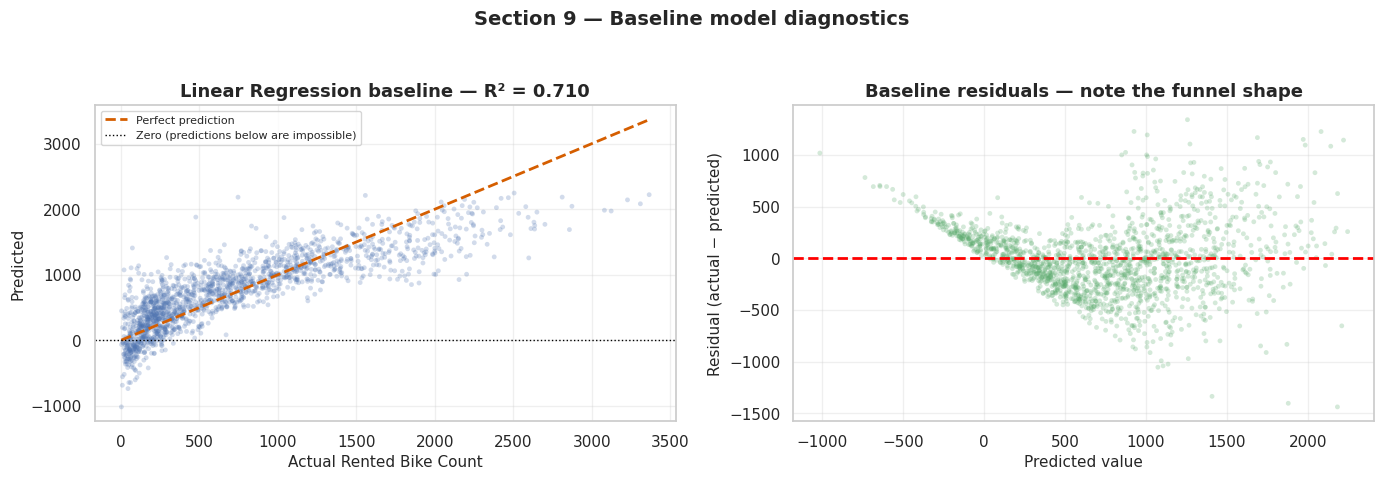

Baseline predictions below zero: 157 of 1693 (9.3%)  — physically impossible


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

axes[0].scatter(y_test, linear_pred, alpha=0.25, s=12, edgecolor="none", color="#4C72B0")
lo, hi = float(y_test.min()), float(y_test.max())
axes[0].plot([lo, hi], [lo, hi], "r--", lw=2, label="Perfect prediction")
axes[0].axhline(0, color="black", lw=1, ls=":", label="Zero (predictions below are impossible)")
axes[0].set_xlabel("Actual Rented Bike Count")
axes[0].set_ylabel("Predicted")
axes[0].set_title(f"Linear Regression baseline — R² = {linear_metrics['R2']:.3f}")
axes[0].legend(fontsize=8)

residuals = y_test - linear_pred
axes[1].scatter(linear_pred, residuals, alpha=0.25, s=12, edgecolor="none", color="#55A868")
axes[1].axhline(0, color="red", ls="--", lw=2)
axes[1].set_xlabel("Predicted value")
axes[1].set_ylabel("Residual (actual − predicted)")
axes[1].set_title("Baseline residuals — note the funnel shape")

fig.suptitle("Section 9 — Baseline model diagnostics", y=1.04,
             fontsize=14, fontweight="bold")
plt.tight_layout()
save_figure("reg_baseline_diagnostics", fig)
plt.show()

n_negative = int((linear_pred < 0).sum())
print(f"Baseline predictions below zero: {n_negative} of {len(linear_pred)} "
      f"({100 * n_negative / len(linear_pred):.1f}%)  — physically impossible")

**Observation.** The Linear Regression baseline explains a moderate share of
the variance and clearly beats the dummy, so the features do carry real
signal. But three problems are visible:

1. The scatter fans out badly at high demand — the model systematically
   **underpredicts busy hours**, exactly the hours that matter operationally.
2. A meaningful number of predictions are **negative**, which is impossible
   for a count of rented bicycles.
3. The residual plot shows a clear **funnel**: errors are small for low
   predictions and large for high ones. This is the **heteroscedasticity**
   that Notebook 03 §5.F.1 predicted from the growing spread in the hourly
   boxplots. The prediction was made in advance and is now confirmed.

**Interpretation.** All three symptoms have the same root cause: a linear
model must represent every relationship as a straight line and must add
effects rather than combine them. Notebook 03 documented an inverted-U
temperature curve, a threshold effect for rain, and a season × hour
interaction — none of which fit that form. The baseline is doing as well as a
straight line can on data whose structure is not straight.

**This establishes the bar.** The ten models in Notebook 07 must beat these
numbers to have earned their complexity. We now have the reference point that
makes their scores meaningful instead of merely impressive-sounding.

---
## 8.6 / 9.1 Leakage-prevention checklist

| Requirement | How it is satisfied here |
|---|---|
| Split before any fitting | `train_test_split` runs in §8.3; the first `.fit()` anywhere is in §8.5 |
| Scaler fitted on train only | Inside the `Pipeline`; `.fit()` sees training rows, `.transform()` handles the test set |
| Encoder fitted on train only | Same mechanism; `handle_unknown="ignore"` covers unseen categories |
| Imputer fitted on train only | Same mechanism |
| Test set untouched until final evaluation | Only used in `.predict()` calls; never in any `.fit()` |
| No target-derived features | Notebook 05 §7.6 rejected every target-encoding candidate |
| Same split for all 10 models | The split is saved below and loaded unchanged by Notebooks 07–09 |
| CV respects the pipeline | `cross_val_score` receives the whole `Pipeline`, so preprocessing is refitted per fold |

---
## Handover to Notebook 07

We save the frozen split together with the **unfitted** preprocessor
definition. Saving it unfitted is deliberate: each of the ten models will
receive a fresh clone inside its own pipeline, so no fitted state can leak
between models or across folds.

In [12]:
split_bundle = {
    "X_train": X_train,
    "X_test": X_test,
    "y_train": y_train,
    "y_test": y_test,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "preprocessor": preprocessor,      # UNFITTED definition
    "feature_names_out": feature_names,
    "baseline_table": baseline_table,
    "random_state": RANDOM_STATE,
}

save_artifact(split_bundle, "reg_06_split")

print(f"\nFrozen split: train {X_train.shape}, test {X_test.shape}")
print(f"Baseline to beat: R² = {linear_metrics['R2']:.4f}, "
      f"RMSE = {linear_metrics['RMSE']:.1f}, MAE = {linear_metrics['MAE']:.1f}")
print("\nNotebook 06 complete.")
print("Next: 07_regression_all_10_models.ipynb")

[saved]  artifacts/reg_06_split.joblib

Frozen split: train (6772, 25), test (1693, 25)
Baseline to beat: R² = 0.7100, RMSE = 337.4, MAE = 255.7

Notebook 06 complete.
Next: 07_regression_all_10_models.ipynb
